170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Number of training images: 50000
Image shape: 32x32 pixels with 3 color channels (RGB)


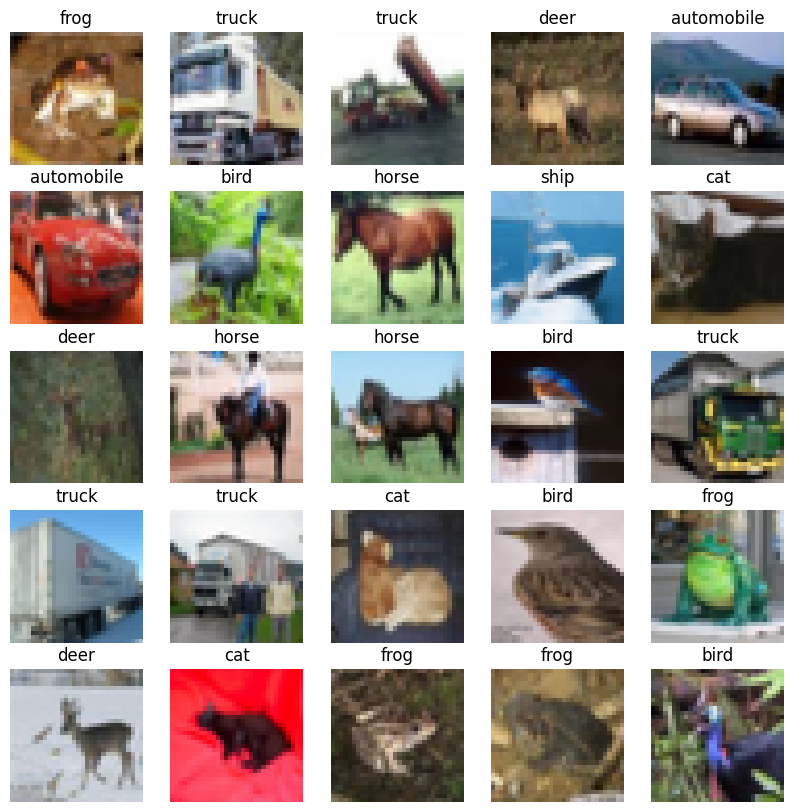

In [1]:
# Step 1: Import libraries and load the CIFAR-10 dataset
import tensorflow as tf
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
import matplotlib.pyplot as plt
import numpy as np

# Load the CIFAR-10 dataset
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

# Define the class names for CIFAR-10
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

# Explore the data
print(f"Number of training images: {x_train.shape[0]}")
print(f"Image shape: {x_train.shape[1]}x{x_train.shape[2]} pixels with {x_train.shape[3]} color channels (RGB)")

# Display a few sample images
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(x_train[i])
    # y_train is a 2D array, so we access the label with y_train[i][0]
    plt.title(class_names[y_train[i][0]])
    plt.axis('off')
plt.show()

In [2]:
# Step 2: Preprocess the data
# Normalize pixel values to be between 0 and 1
x_train = x_train / 255.0
x_test = x_test / 255.0

In [3]:
# Step 3: Build the Convolutional Neural Network (CNN) model

model = Sequential([
    # First Convolutional Block
    # 32 filters of size 3x3. 'relu' activation.
    # 'input_shape' is only needed for the first layer.
    Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),
    MaxPooling2D((2, 2)),

    # Second Convolutional Block
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    # Third Convolutional Block (optional, for deeper learning)
    Conv2D(64, (3, 3), activation='relu'),

    # Flatten the results to feed into a dense layer
    Flatten(),

    # Dense hidden layer
    Dense(64, activation='relu'),

    # Output layer with 10 neurons
    Dense(10, activation='softmax')
])

# Print a summary of the model
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
# Step 4: Compile and train the model

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

print("\nStarting CNN training...")
# Let's train for more epochs this time as the task is harder
history = model.fit(x_train, y_train, epochs=10,
                    validation_data=(x_test, y_test))
print("Training finished!")


Starting CNN training...
Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 45s 28ms/step - accuracy: 0.3518 - loss: 1.7580 - val_accuracy: 0.5493 - val_loss: 1.2676
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 44s 28ms/step - accuracy: 0.5811 - loss: 1.1782 - val_accuracy: 0.6212 - val_loss: 1.0848
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 85s 30ms/step - accuracy: 0.6454 - loss: 1.0134 - val_accuracy: 0.6582 - val_loss: 0.9744
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 79s 28ms/step - accuracy: 0.6855 - loss: 0.9079 - val_accuracy: 0.6787 - val_loss: 0.9223
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 46s 29ms/step - accuracy: 0.7118 - loss: 0.8250 - val_accuracy: 0.6991 - val_loss: 0.8775
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 43s 28ms/step - accuracy: 0.7276 - loss: 0.7658 - val_accuracy: 0.7076 - val_loss: 0.8662
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 46s 30ms/step - accuracy: 0.7557 - loss: 0.6989 - val_accuracy: 0.7070 - val_loss: 0.8551
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 47s 30ms

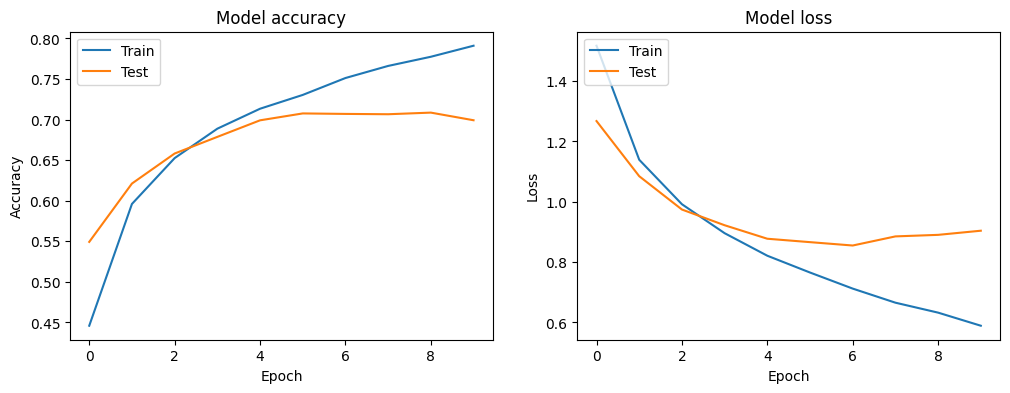

313/313 - 2s - 8ms/step - accuracy: 0.6992 - loss: 0.9041

Final Test accuracy: 69.92%


In [5]:
# Step 5: Evaluate the model and visualize the training process

# Plot training & validation accuracy values
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

# Final evaluation on the test set
test_loss, test_acc = model.evaluate(x_test,  y_test, verbose=2)
print(f'\nFinal Test accuracy: {test_acc*100:.2f}%')

In [ ]:
# Step 6: Make predictions

# Get predictions for the first 25 images in the test set
predictions = model.predict(x_test[:25])

# Display the results
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(x_test[i])

    predicted_label = np.argmax(predictions[i])
    true_label = y_test[i][0]

    color = 'green' if predicted_label == true_label else 'red'
    plt.title(f"Pred: {class_names[predicted_label]}\nTrue: {class_names[true_label]}", color=color, fontsize=8)
    plt.axis('off')
plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step
